In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import scipy.linalg as la

In [3]:
# -- Definition of constants --
b = 4.0

In [ ]:
# -- Definition of functions for Matrix Method --

def matrix_method(V, Nmax, b, dim='1D', m_quant=0):
    """_summary_

    Args:
        V (_type_): _description_
        Nmax (_type_): _description_
        b (_type_): _description_
        dim (str, optional): _description_. Defaults to '1D'.
        m_quant (int, optional): _description_. Defaults to 0.

    Returns:
        _type_: _description_
    """
    def basis_func(n, x):
        return np.sqrt(2.0/b) * np.sin(n * np.pi * x / b)
    
    H = np.zeros((Nmax, Nmax))
    
    # First the elements in the diagonal
    E_0 = [(n**2 * np.pi**2) / (2.0 * b**2) for n in range(1, Nmax + 1)]
    
    # Populate the diagonal elements in the matrix
    for i in range(Nmax):
        H[i,i] = E_0[i]
        
    def Veff(x):
        if dim =='1D':
            return V(x)
        elif dim =='2D_radial':
            if x <= 1e-12:
                return V(x)
            centrifugal_term = (m_quant**2 - 0.25) / (2.0 * x**2)
            return V(x) + centrifugal_term
    
    # Now we will compute the other matrix elements by using nested loops and
    # numerical integration. 
    for n in range(Nmax):
        n_index = n + 1
        for m in range(Nmax): 
            m_index = m + 1
            integrand = lambda x: basis_func(n_index, x) * Veff(x) * basis_func(m_index, x)
            V_nm, _ = quad(integrand, 0.0, b, limit=100)
            H[n, m] += V_nm
            
    energies, vectors = la.eigh(H)
    return H, energies, vectors

def reconstruct_wavefunction(vectors, b, Nmax):
    """_summary_

    Args:
        Cn (_type_): _description_
        b (_type_): _description_
        Nmax (_type_): _description_

    Returns:
        _type_: _description_
    """
    x_grid = np.linspace(0, b, 1000)
    n_indices = np.arange(1, Nmax + 1)
    Phi = np.sqrt(2.0 / b) * np.sin(np.outer(x_grid, n_indices * np.pi / b))
    Psi = Phi @ vectors
    return Psi, np.abs(Psi)**2 # This returns a 2D matrix with Nmax amount of functions for different energies eigenvalues for a 1000 values of x.



In [23]:
b = 4.0
V0 = 50.0

def single_well(x):
    return 0.0 if abs(x - b/2.0) <= 0.5 else V0

# Build 1D Hamiltonian
matrix, energies, vectors = matrix_method(single_well, Nmax=10, b=b, dim='1D')
Psi, prob_density = reconstruct_wavefunction(vectors, b, Nmax=10)

(1000, 10)
(10, 10)
(1000, 10)


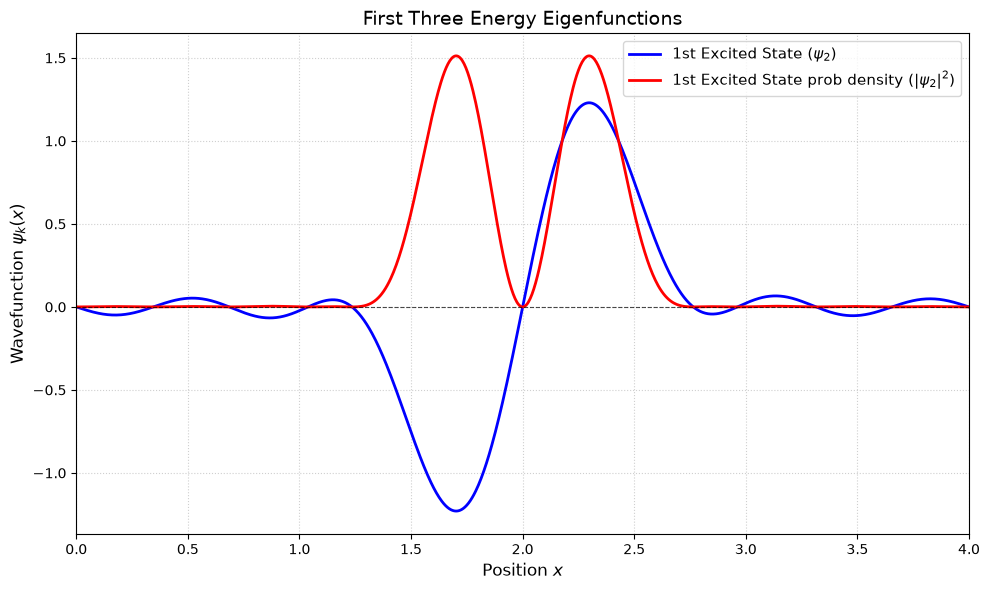

In [27]:
x_grid = np.linspace(0, 4, 1000)

# 3. Create the plot
plt.figure(figsize=(10, 6))

plt.plot(x_grid, Psi[:, 1], label=r'1st Excited State ($\psi_2$)', color='blue', linewidth=2)
plt.plot(x_grid, prob_density[:, 1], label=r'1st Excited State prob density ($|\psi_2|^2$)', color='red', linewidth=2)

# Reference horizontal axis and styling
plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.title("First Three Energy Eigenfunctions", fontsize=14)
plt.xlabel("Position $x$", fontsize=12)
plt.ylabel(r"Wavefunction $\psi_k(x)$", fontsize=12)
plt.xlim(0, b)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

In [13]:
print(np.linspace(0, 1, 11))
print(np.arange(1,11))
print(np.outer(np.linspace(0, 1, 11), np.arange(1,10)))

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
[ 1  2  3  4  5  6  7  8  9 10]
[[0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
 [0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8]
 [0.3 0.6 0.9 1.2 1.5 1.8 2.1 2.4 2.7]
 [0.4 0.8 1.2 1.6 2.  2.4 2.8 3.2 3.6]
 [0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5]
 [0.6 1.2 1.8 2.4 3.  3.6 4.2 4.8 5.4]
 [0.7 1.4 2.1 2.8 3.5 4.2 4.9 5.6 6.3]
 [0.8 1.6 2.4 3.2 4.  4.8 5.6 6.4 7.2]
 [0.9 1.8 2.7 3.6 4.5 5.4 6.3 7.2 8.1]
 [1.  2.  3.  4.  5.  6.  7.  8.  9. ]]
